In [ ]:
!pip install torch torchvision matplotlib numpy grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 106.1 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for grad-cam: filename=grad_cam-1.5.5-py3-none-any.whl size=44286 sha256=461068db61f9a8acb05c6ea0bb05de25169b07ecb10a1f8f387b78dde8b1c018
  Stored in directory: /root/.cache/pip/wheels/fb/3b/09/2afc520f3d69bc26ae6bd87416759c820a3f7d05c1a077bbf6
Successfully built grad-cam


In [ ]:
import torch
import torchvision
import torchvision.transforms as transforms
import torch.nn as nn
import torch.nn.functional as F


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# 1. Transform MNIST to match SVHN (32x32, 3 RGB channels)
mnist_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
])

# 2. SVHN just needs to be a Tensor
svhn_transform = transforms.Compose([
    transforms.ToTensor(),
])

# 3. Load Datasets (Colab will download these to a hidden /data folder)
mnist_train = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=mnist_transform)
svhn_test = torchvision.datasets.SVHN(root='./data', split='test', download=True, transform=svhn_transform)

# 4. Create DataLoaders
mnist_loader = torch.utils.data.DataLoader(mnist_train, batch_size=128, shuffle=True)
svhn_loader = torch.utils.data.DataLoader(svhn_test, batch_size=1, shuffle=True)

# 5. Define Model
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(32 * 8 * 8, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(-1, 32 * 8 * 8)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

model = SimpleCNN().to(device)

Using device: cuda


100%|██████████| 9.91M/9.91M [00:00<00:00, 19.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 481kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.48MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.93MB/s]
100%|██████████| 64.3M/64.3M [00:03<00:00, 20.9MB/s]


In [ ]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("Starting Baseline Training on MNIST...")
model.train()

for epoch in range(5):
    running_loss = 0.0
    for i, data in enumerate(mnist_loader, 0):
        # Move data to GPU
        inputs, labels = data[0].to(device), data[1].to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        if i % 100 == 99:
            print(f'[Epoch {epoch + 1}, Batch {i + 1}] Loss: {running_loss / 100:.3f}')
            running_loss = 0.0

print("Finished Phase 1 Baseline Training!")

Starting Baseline Training on MNIST...
[Epoch 1, Batch 100] Loss: 0.781
[Epoch 1, Batch 200] Loss: 0.232
[Epoch 1, Batch 300] Loss: 0.159
[Epoch 1, Batch 400] Loss: 0.126
[Epoch 2, Batch 100] Loss: 0.092
[Epoch 2, Batch 200] Loss: 0.082
[Epoch 2, Batch 300] Loss: 0.078
[Epoch 2, Batch 400] Loss: 0.068
[Epoch 3, Batch 100] Loss: 0.052
[Epoch 3, Batch 200] Loss: 0.050
[Epoch 3, Batch 300] Loss: 0.055
[Epoch 3, Batch 400] Loss: 0.049
[Epoch 4, Batch 100] Loss: 0.037
[Epoch 4, Batch 200] Loss: 0.042
[Epoch 4, Batch 300] Loss: 0.036
[Epoch 4, Batch 400] Loss: 0.037
[Epoch 5, Batch 100] Loss: 0.025
[Epoch 5, Batch 200] Loss: 0.030
[Epoch 5, Batch 300] Loss: 0.032
[Epoch 5, Batch 400] Loss: 0.032
Finished Phase 1 Baseline Training!


Starting Baseline Training & Evaluation on MNIST...
Epoch [1/5] | Train Loss: 0.0286, Train Acc: 99.08% | Test Loss: 0.0310, Test Acc: 98.91%
Epoch [2/5] | Train Loss: 0.0206, Train Acc: 99.35% | Test Loss: 0.0295, Test Acc: 98.90%
Epoch [3/5] | Train Loss: 0.0183, Train Acc: 99.41% | Test Loss: 0.0312, Test Acc: 99.04%
Epoch [4/5] | Train Loss: 0.0133, Train Acc: 99.56% | Test Loss: 0.0337, Test Acc: 98.93%
Epoch [5/5] | Train Loss: 0.0095, Train Acc: 99.68% | Test Loss: 0.0337, Test Acc: 98.98%

Finished Phase 1 Baseline Training! Generating plots...


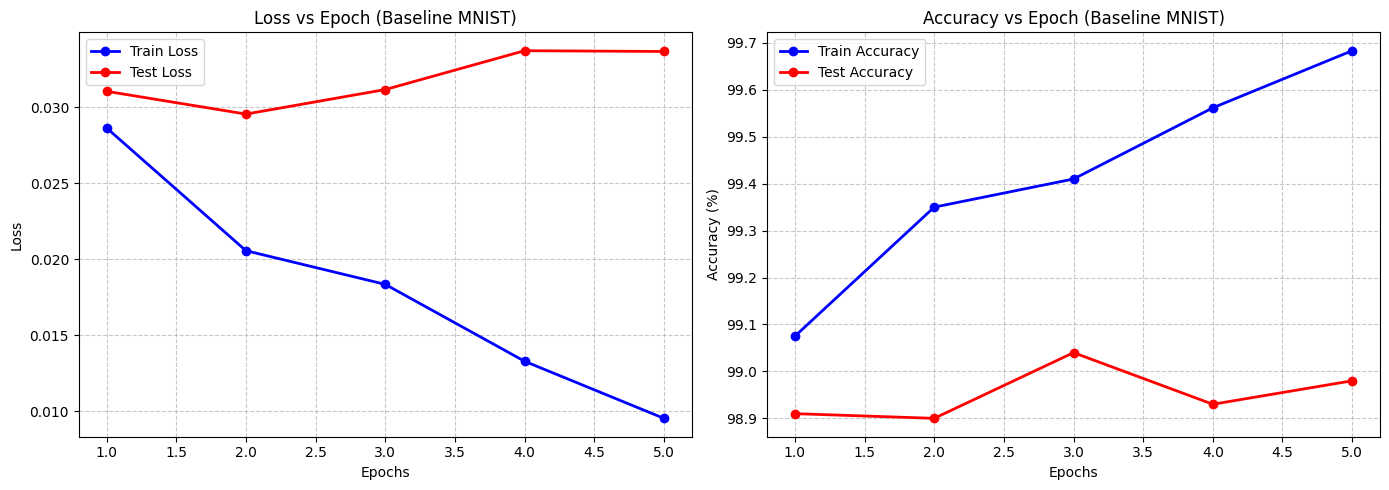

In [ ]:
import torch.optim as optim
import matplotlib.pyplot as plt

# --- 1. Quick Data Update: Load the MNIST Test Set ---
mnist_test_data = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=mnist_transform)
mnist_test_loader = torch.utils.data.DataLoader(mnist_test_data, batch_size=128, shuffle=False)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# --- 2. Trackers for Plotting ---
train_losses, test_losses = [], []
train_accs, test_accs = [], []

print("Starting Baseline Training & Evaluation on MNIST...")

for epoch in range(5):
    # ==========================
    #      TRAINING PHASE
    # ==========================
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for inputs, labels in mnist_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # Track Loss
        running_loss += loss.item() * inputs.size(0)

        # Track Accuracy
        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    # Calculate average metrics for the epoch
    epoch_train_loss = running_loss / len(mnist_loader.dataset)
    epoch_train_acc = 100 * correct_train / total_train
    train_losses.append(epoch_train_loss)
    train_accs.append(epoch_train_acc)

    # ==========================
    #      EVALUATION PHASE
    # ==========================
    model.eval()
    test_loss = 0.0
    correct_test = 0
    total_test = 0

    with torch.no_grad(): # Disable gradients for testing to save memory and speed up
        for inputs, labels in mnist_test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            # Track Loss
            test_loss += loss.item() * inputs.size(0)

            # Track Accuracy
            _, predicted = torch.max(outputs.data, 1)
            total_test += labels.size(0)
            correct_test += (predicted == labels).sum().item()

    # Calculate average metrics for the epoch
    epoch_test_loss = test_loss / len(mnist_test_loader.dataset)
    epoch_test_acc = 100 * correct_test / total_test
    test_losses.append(epoch_test_loss)
    test_accs.append(epoch_test_acc)

    # Print epoch summary
    print(f'Epoch [{epoch+1}/5] | '
          f'Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc:.2f}% | '
          f'Test Loss: {epoch_test_loss:.4f}, Test Acc: {epoch_test_acc:.2f}%')

print("\nFinished Phase 1 Baseline Training! Generating plots...")

# ==========================
#      PLOTTING PHASE
# ==========================
epochs_range = range(1, 6)

fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Train vs Test Loss
axs[0].plot(epochs_range, train_losses, label='Train Loss', marker='o', color='blue', linewidth=2)
axs[0].plot(epochs_range, test_losses, label='Test Loss', marker='o', color='red', linewidth=2)
axs[0].set_title('Loss vs Epoch (Baseline MNIST)')
axs[0].set_xlabel('Epochs')
axs[0].set_ylabel('Loss')
axs[0].legend()
axs[0].grid(True, linestyle='--', alpha=0.7)

# Plot 2: Train vs Test Accuracy
axs[1].plot(epochs_range, train_accs, label='Train Accuracy', marker='o', color='blue', linewidth=2)
axs[1].plot(epochs_range, test_accs, label='Test Accuracy', marker='o', color='red', linewidth=2)
axs[1].set_title('Accuracy vs Epoch (Baseline MNIST)')
axs[1].set_xlabel('Epochs')
axs[1].set_ylabel('Accuracy (%)')
axs[1].legend()
axs[1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


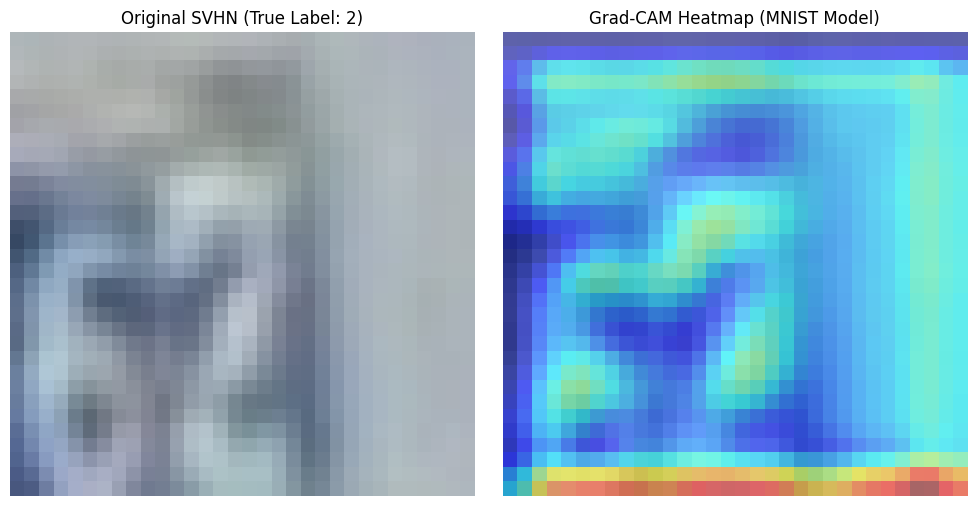

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# Set model to evaluation mode
model.eval()

# 1. Target the last convolutional layer
target_layers = [model.conv2]

# 2. Initialize CAM
cam = GradCAM(model=model, target_layers=target_layers)

# 3. Grab ONE image from the SVHN test set
svhn_image, label = next(iter(svhn_loader))
input_tensor = svhn_image.to(device) # Move to GPU for the model

# 4. Generate the heatmap
targets = [ClassifierOutputTarget(label.item())]
grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]

# 5. Overlay the heatmap
# We must move the original image back to the CPU for matplotlib to plot it
rgb_img = svhn_image.squeeze().cpu().permute(1, 2, 0).numpy()
visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

# 6. Plot and Save
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(rgb_img)
ax[0].set_title(f"Original SVHN (True Label: {label.item()})")
ax[0].axis('off')

ax[1].imshow(visualization)
ax[1].set_title("Grad-CAM Heatmap (MNIST Model)")
ax[1].axis('off')

plt.tight_layout()
plt.show()

# Optional: Save this to your Colab files to download for your report
fig.savefig("baseline_drift_visualization.png")

Generating Heatmaps. (Note: ScoreCAM and AblationCAM might take a few seconds...)


100%|██████████| 1/1 [00:00<00:00, 69.24it/s]


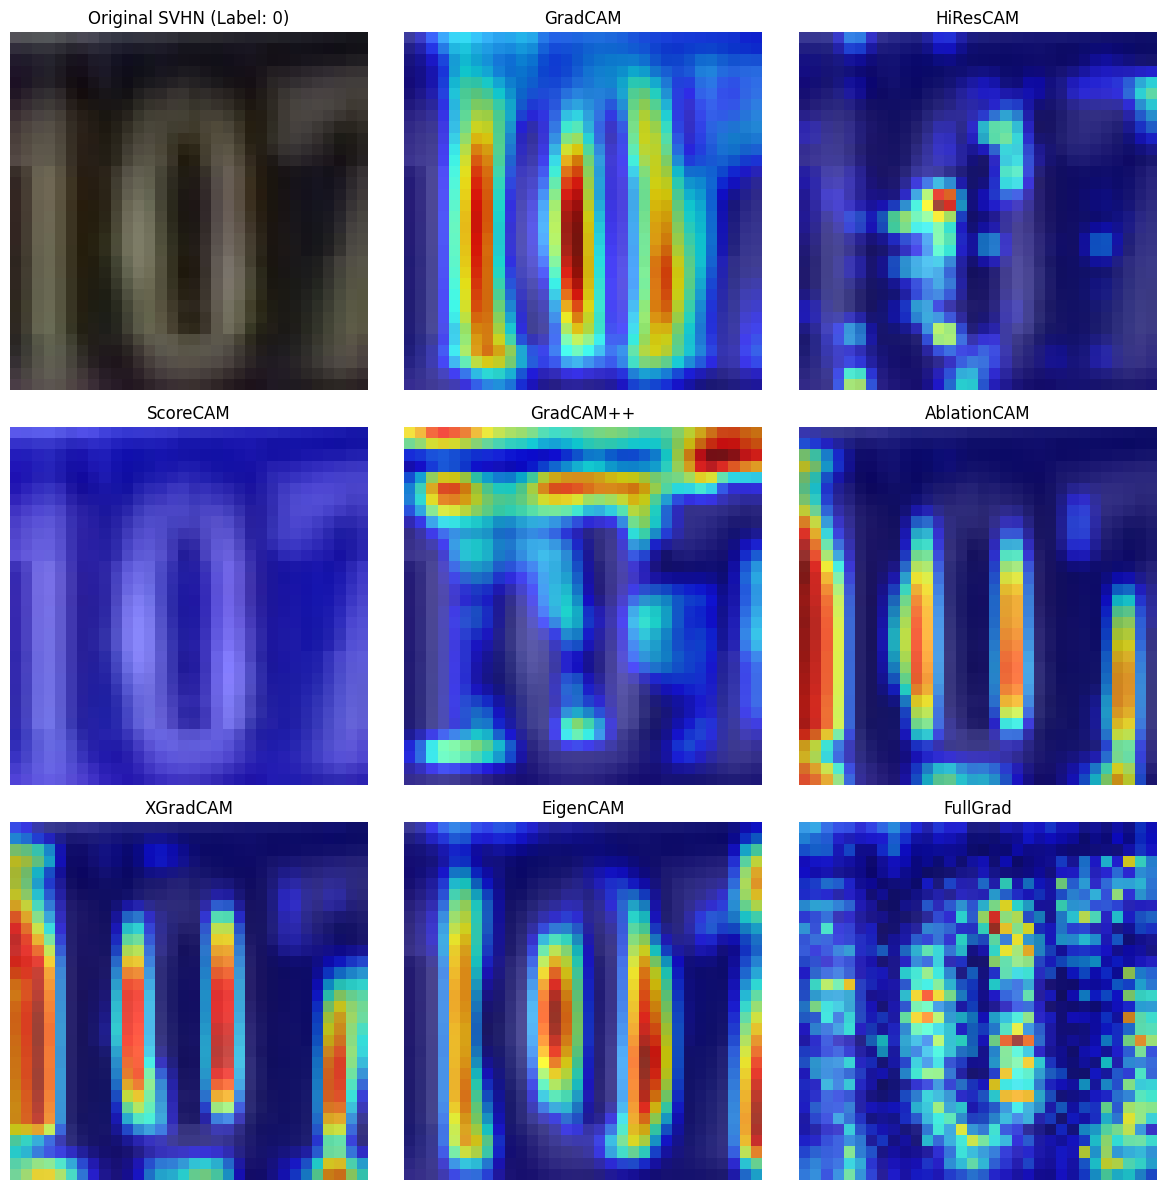

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from pytorch_grad_cam import (
    GradCAM, HiResCAM, ScoreCAM, GradCAMPlusPlus,
    AblationCAM, XGradCAM, EigenCAM, FullGrad
)
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# 1. Set model to evaluation mode & define target layer
model.eval()
target_layers = [model.conv2]

# 2. Grab ONE image from the SVHN test set
svhn_image, label = next(iter(svhn_loader))
input_tensor = svhn_image.to(device)

# 3. Create a dictionary of all the CAM methods you want to test
cam_algorithms = {
    "GradCAM": GradCAM,
    "HiResCAM": HiResCAM,
    "ScoreCAM": ScoreCAM,
    "GradCAM++": GradCAMPlusPlus,
    "AblationCAM": AblationCAM,
    "XGradCAM": XGradCAM,
    "EigenCAM": EigenCAM,
    "FullGrad": FullGrad
}

# Target the true label
targets = [ClassifierOutputTarget(label.item())]

# Prepare the original image for plotting
rgb_img = svhn_image.squeeze().cpu().permute(1, 2, 0).numpy()

# 4. Set up a 3x3 grid for plotting
fig, axes = plt.subplots(3, 3, figsize=(12, 12))
axes = axes.flatten()

# Plot the original image in the first slot
axes[0].imshow(rgb_img)
axes[0].set_title(f"Original SVHN (Label: {label.item()})")
axes[0].axis('off')

print("Generating Heatmaps. (Note: ScoreCAM and AblationCAM might take a few seconds...)")

# 5. Loop through each algorithm, generate the heatmap, and plot it
for i, (name, cam_class) in enumerate(cam_algorithms.items()):
    # Initialize the specific CAM method
    # Note: ScoreCAM and AblationCAM require batching, handled automatically by the library
    with cam_class(model=model, target_layers=target_layers) as cam:
        grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
        visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

        # Plot in the next available slot (i+1 because slot 0 is the original)
        axes[i + 1].imshow(visualization)
        axes[i + 1].set_title(name)
        axes[i + 1].axis('off')

plt.tight_layout()
plt.show()

# Save for your report!
fig.savefig("multi_cam_comparison.png", dpi=300)

## Drift Visualization Using Pretrained Model (ResNet)

Starting ResNet Training & Evaluation on MNIST...
Epoch [1/5] | Train Loss: 0.0660, Train Acc: 97.96% | Test Loss: 0.0576, Test Acc: 98.08%
Epoch [2/5] | Train Loss: 0.0350, Train Acc: 98.94% | Test Loss: 0.0326, Test Acc: 99.06%
Epoch [3/5] | Train Loss: 0.0269, Train Acc: 99.20% | Test Loss: 0.0274, Test Acc: 99.08%
Epoch [4/5] | Train Loss: 0.0230, Train Acc: 99.27% | Test Loss: 0.0214, Test Acc: 99.34%
Epoch [5/5] | Train Loss: 0.0182, Train Acc: 99.42% | Test Loss: 0.0242, Test Acc: 99.27%

Finished ResNet Baseline Training! Generating plots...


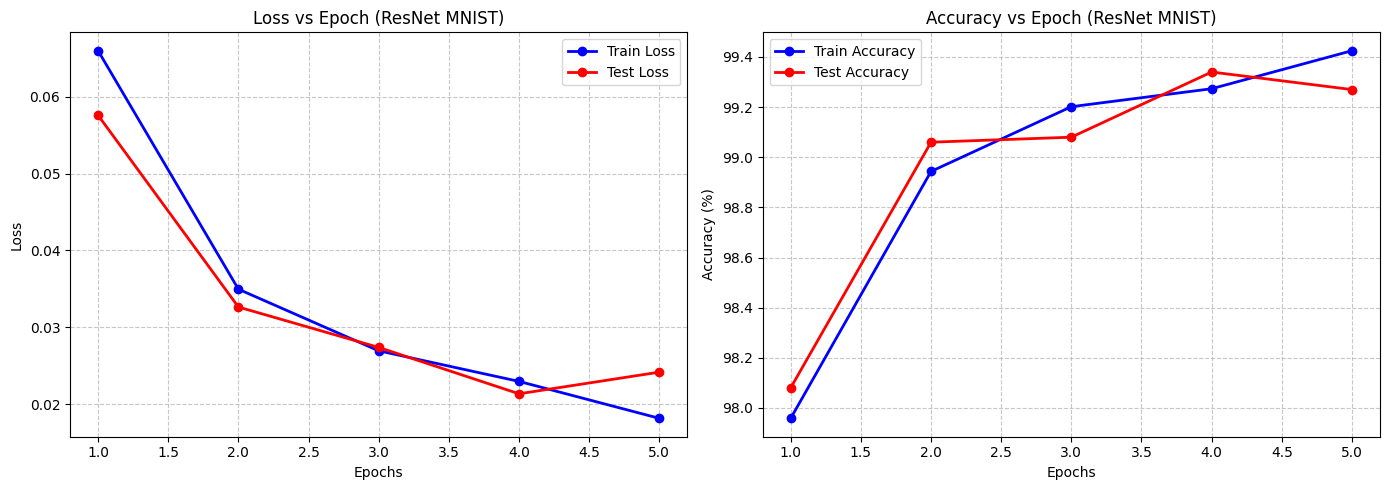

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- 1. ResNet Data Setup (Upscaling to 224x224 & Normalizing) ---
resnet_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3), # Fake RGB for MNIST
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

svhn_resnet_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

mnist_train_resnet = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=resnet_transform)
mnist_test_resnet = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=resnet_transform)
svhn_test_resnet = torchvision.datasets.SVHN(root='./data', split='test', download=True, transform=svhn_resnet_transform)

mnist_loader_resnet = torch.utils.data.DataLoader(mnist_train_resnet, batch_size=64, shuffle=True)
mnist_test_loader_resnet = torch.utils.data.DataLoader(mnist_test_resnet, batch_size=64, shuffle=False)
svhn_loader_resnet = torch.utils.data.DataLoader(svhn_test_resnet, batch_size=1, shuffle=True)

# --- 2. Load Pretrained ResNet18 ---
resnet_model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Change the final fully connected layer to output 10 classes (digits 0-9)
num_ftrs = resnet_model.fc.in_features
resnet_model.fc = nn.Linear(num_ftrs, 10)
resnet_model = resnet_model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(resnet_model.parameters(), lr=0.001)

# --- 3. Trackers for Plotting ---
train_losses, test_losses = [], []
train_accs, test_accs = [], []

print("Starting ResNet Training & Evaluation on MNIST...")

for epoch in range(5):
    # ==========================
    #      TRAINING
    # ==========================
    resnet_model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for inputs, labels in mnist_loader_resnet:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = resnet_model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # Track Loss
        running_loss += loss.item() * inputs.size(0)

        # Track Accuracy
        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    # Calculate average metrics for the epoch
    epoch_train_loss = running_loss / len(mnist_loader_resnet.dataset)
    epoch_train_acc = 100 * correct_train / total_train
    train_losses.append(epoch_train_loss)
    train_accs.append(epoch_train_acc)

    # ==========================
    #      EVALUATION
    # ==========================
    resnet_model.eval()
    test_loss = 0.0
    correct_test = 0
    total_test = 0

    with torch.no_grad(): # Disable gradients for testing
        for inputs, labels in mnist_test_loader_resnet:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = resnet_model(inputs)
            loss = criterion(outputs, labels)

            # Track Loss
            test_loss += loss.item() * inputs.size(0)

            # Track Accuracy
            _, predicted = torch.max(outputs.data, 1)
            total_test += labels.size(0)
            correct_test += (predicted == labels).sum().item()

    # Calculate average metrics for the epoch
    epoch_test_loss = test_loss / len(mnist_test_loader_resnet.dataset)
    epoch_test_acc = 100 * correct_test / total_test
    test_losses.append(epoch_test_loss)
    test_accs.append(epoch_test_acc)

    # Print epoch summary
    print(f'Epoch [{epoch+1}/5] | '
          f'Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc:.2f}% | '
          f'Test Loss: {epoch_test_loss:.4f}, Test Acc: {epoch_test_acc:.2f}%')

print("\nFinished ResNet Baseline Training! Generating plots...")

#      PLOTTING
# ==========================
epochs_range = range(1, 6)

fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Train vs Test Loss
axs[0].plot(epochs_range, train_losses, label='Train Loss', marker='o', color='blue', linewidth=2)
axs[0].plot(epochs_range, test_losses, label='Test Loss', marker='o', color='red', linewidth=2)
axs[0].set_title('Loss vs Epoch (ResNet MNIST)')
axs[0].set_xlabel('Epochs')
axs[0].set_ylabel('Loss')
axs[0].legend()
axs[0].grid(True, linestyle='--', alpha=0.7)

# Plot 2: Train vs Test Accuracy
axs[1].plot(epochs_range, train_accs, label='Train Accuracy', marker='o', color='blue', linewidth=2)
axs[1].plot(epochs_range, test_accs, label='Test Accuracy', marker='o', color='red', linewidth=2)
axs[1].set_title('Accuracy vs Epoch (ResNet MNIST)')
axs[1].set_xlabel('Epochs')
axs[1].set_ylabel('Accuracy (%)')
axs[1].legend()
axs[1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

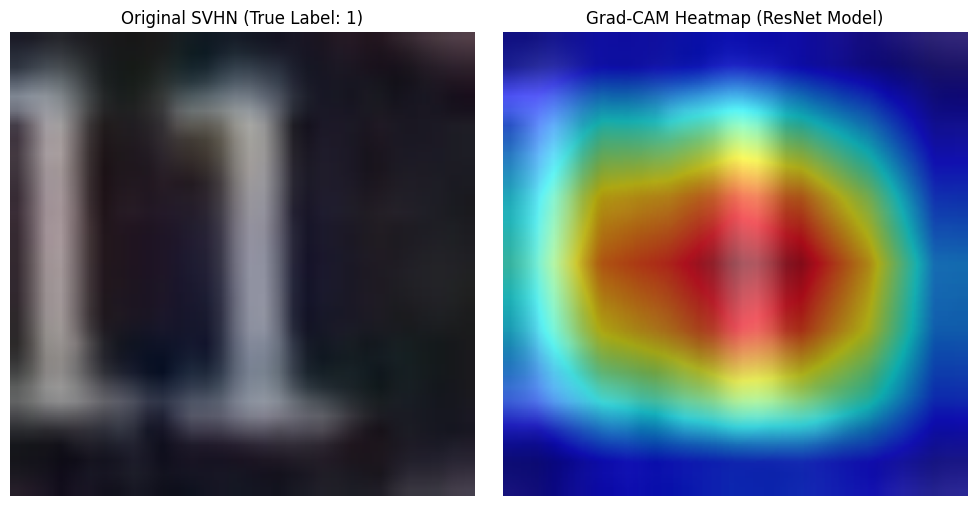

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# Model to evaluation mode
resnet_model.eval()

# 1. Target the final block of ResNet18
target_layers = [resnet_model.layer4[-1]]

# 2. Initialize CAM
cam = GradCAM(model=resnet_model, target_layers=target_layers)

# 3. Grab ONE image from the SVHN test set
svhn_image, label = next(iter(svhn_loader_resnet))
input_tensor = svhn_image.to(device)

# 4. Generate the heatmap
targets = [ClassifierOutputTarget(label.item())]
grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]

# 5. Overlay the heatmap
inv_normalize = transforms.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)
rgb_img = inv_normalize(svhn_image.squeeze()).cpu().permute(1, 2, 0).numpy()
rgb_img = np.clip(rgb_img, 0, 1)

visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

# 6. Plot and Save
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(rgb_img)
ax[0].set_title(f"Original SVHN (True Label: {label.item()})")
ax[0].axis('off')

ax[1].imshow(visualization)
ax[1].set_title("Grad-CAM Heatmap (ResNet Model)")
ax[1].axis('off')

plt.tight_layout()
plt.show()
fig.savefig("resnet_drift_visualization.png")

Generating ResNet Heatmaps...


100%|██████████| 16/16 [00:00<00:00, 35.38it/s]


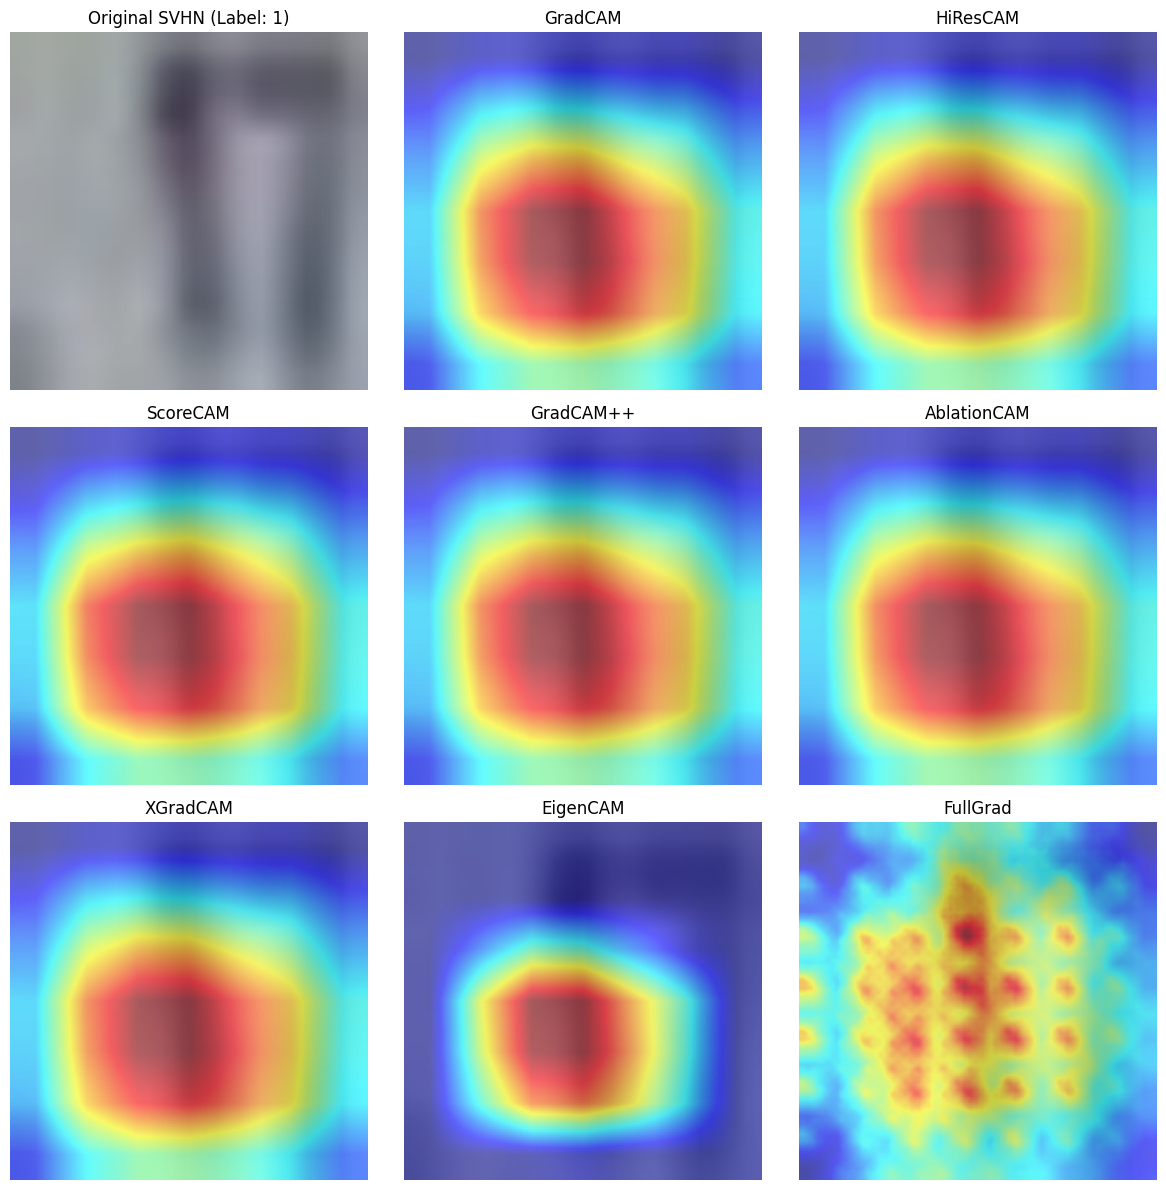

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from pytorch_grad_cam import (
    GradCAM, HiResCAM, ScoreCAM, GradCAMPlusPlus,
    AblationCAM, XGradCAM, EigenCAM, FullGrad
)
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

resnet_model.eval()
target_layers = [resnet_model.layer4[-1]]

# 2. image from the SVHN test set
svhn_image, label = next(iter(svhn_loader_resnet))
input_tensor = svhn_image.to(device)

cam_algorithms = {
    "GradCAM": GradCAM,
    "HiResCAM": HiResCAM,
    "ScoreCAM": ScoreCAM,
    "GradCAM++": GradCAMPlusPlus,
    "AblationCAM": AblationCAM,
    "XGradCAM": XGradCAM,
    "EigenCAM": EigenCAM,
    "FullGrad": FullGrad
}

# Target the true label
targets = [ClassifierOutputTarget(label.item())]

inv_normalize = transforms.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)
rgb_img = inv_normalize(svhn_image.squeeze()).cpu().permute(1, 2, 0).numpy()
rgb_img = np.clip(rgb_img, 0, 1)

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
axes = axes.flatten()
axes[0].imshow(rgb_img)
axes[0].set_title(f"Original SVHN (Label: {label.item()})")
axes[0].axis('off')

print("Generating ResNet Heatmaps...")
for i, (name, cam_class) in enumerate(cam_algorithms.items()):
    with cam_class(model=resnet_model, target_layers=target_layers) as cam:
        grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
        visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)
        axes[i + 1].imshow(visualization)
        axes[i + 1].set_title(name)
        axes[i + 1].axis('off')

plt.tight_layout()
plt.show()

fig.savefig("resnet_multi_cam_comparison.png", dpi=300)

## Applications

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torchvision import transforms
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

resnet_model.eval()
target_layers = [resnet_model.layer4[-1]]

svhn_image, label = next(iter(svhn_loader_resnet))
input_tensor = svhn_image.to(device)
targets = [ClassifierOutputTarget(label.item())]

inv_normalize = transforms.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)
rgb_img = inv_normalize(svhn_image.squeeze()).cpu().permute(1, 2, 0).numpy()
rgb_img = np.clip(rgb_img, 0, 1)

def run_and_plot_cam(cam_class, title):
    with cam_class(model=resnet_model, target_layers=target_layers) as cam:
        grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
        visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

        fig, ax = plt.subplots(1, 2, figsize=(8, 4))
        ax[0].imshow(rgb_img)
        ax[0].set_title(f"Original (Label: {label.item()})")
        ax[0].axis('off')
        ax[1].imshow(visualization)
        ax[1].set_title(title)
        ax[1].axis('off')
        plt.show()

print("Setup Complete! Ready to process CAMs.")

Setup Complete! Ready to process CAMs.


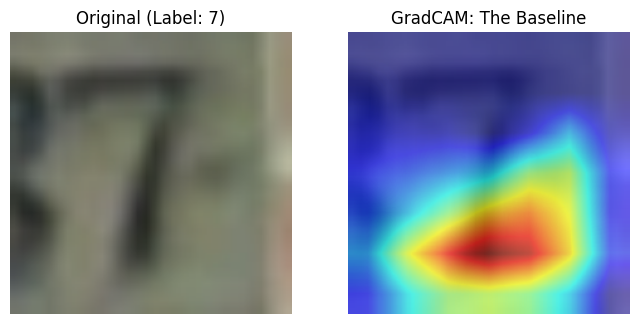

In [ ]:
from pytorch_grad_cam import GradCAM
run_and_plot_cam(GradCAM, "GradCAM: The Baseline")

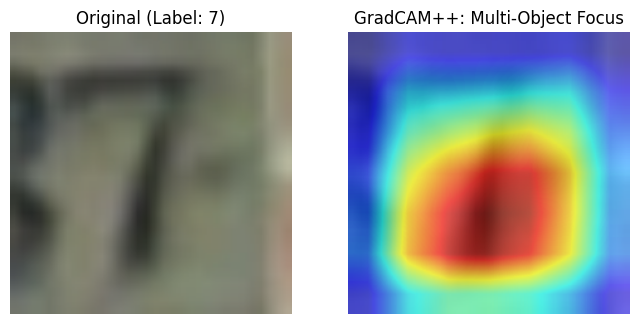

In [ ]:
from pytorch_grad_cam import GradCAMPlusPlus
run_and_plot_cam(GradCAMPlusPlus, "GradCAM++: Multi-Object Focus")

100%|██████████| 32/32 [00:00<00:00, 54.33it/s]


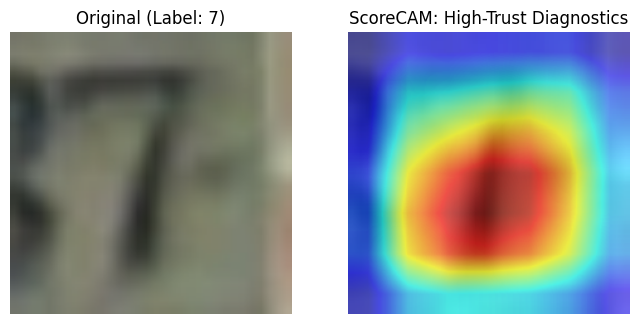

In [ ]:
from pytorch_grad_cam import ScoreCAM
run_and_plot_cam(ScoreCAM, "ScoreCAM: High-Trust Diagnostics")

100%|██████████| 16/16 [00:00<00:00, 31.78it/s]


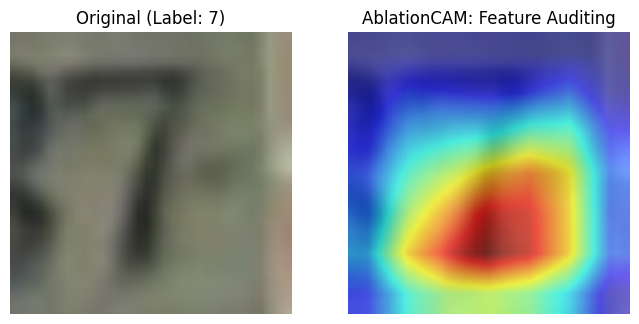

In [ ]:
from pytorch_grad_cam import AblationCAM
run_and_plot_cam(AblationCAM, "AblationCAM: Feature Auditing")

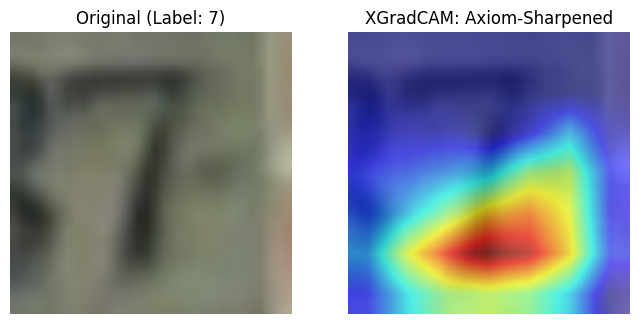

In [ ]:
from pytorch_grad_cam import XGradCAM
run_and_plot_cam(XGradCAM, "XGradCAM: Axiom-Sharpened")

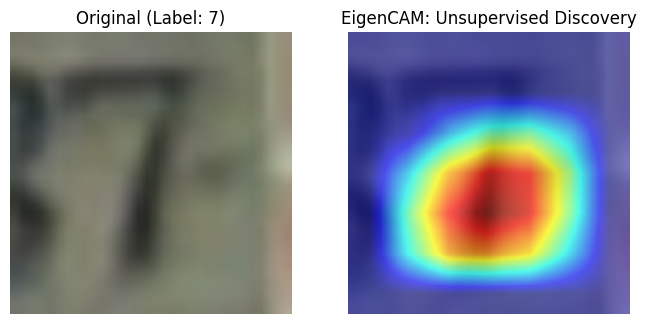

In [ ]:
from pytorch_grad_cam import EigenCAM
run_and_plot_cam(EigenCAM, "EigenCAM: Unsupervised Discovery")

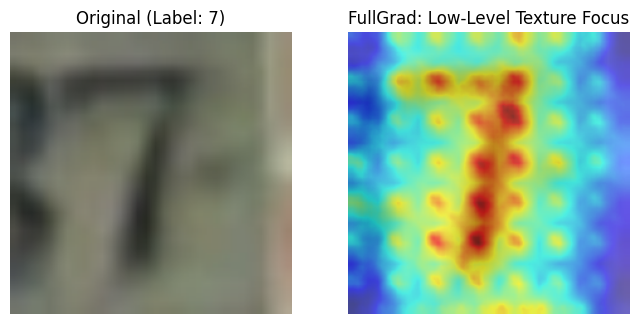

In [ ]:
from pytorch_grad_cam import FullGrad
run_and_plot_cam(FullGrad, "FullGrad: Low-Level Texture Focus")

## Application of Various Cams.
# Visualization of Cancer Cells using `Score Cam`.

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("bhaveshmittal/melanoma-cancer-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'melanoma-cancer-dataset' dataset.
Path to dataset files: /kaggle/input/melanoma-cancer-dataset


In [ ]:
import os
import kagglehub
import torch
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader


print("Downloading Melanoma Dataset from Kaggle...")
path = kagglehub.dataset_download("bhaveshmittal/melanoma-cancer-dataset")
print("Path to dataset files:", path)


resnet_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dir = os.path.join(path, 'train')
test_dir = os.path.join(path, 'test')

train_data = ImageFolder(root=train_dir, transform=resnet_transform)
test_data = ImageFolder(root=test_dir, transform=resnet_transform)

# Batch size 32 is safe for Colab GPUs with ResNet18
train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
test_loader = DataLoader(test_data, batch_size=1, shuffle=True)

class_names = train_data.classes
print(f"Classes found: {class_names}") # Should print ['benign', 'malignant']

Using Colab cache for faster access to the 'melanoma-cancer-dataset' dataset.
Path to dataset files: /kaggle/input/melanoma-cancer-dataset
Classes found: ['Benign', 'Malignant']


In [ ]:
import torchvision.models as models
import torch.nn as nn
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, 2)
model = model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(model.parameters(), lr=0.0001)

print("Starting Model Fine-Tuning...")
model.train()
for epoch in range(10):
    running_loss = 0.0
    for i, (inputs, labels) in enumerate(train_loader):
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        if i % 50 == 49:
            print(f'Batch {i + 1} | Loss: {running_loss / 50:.3f}')
            running_loss = 0.0

print("Training Complete!")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 210MB/s]


Starting Model Fine-Tuning...
Batch 50 | Loss: 0.350
Batch 100 | Loss: 0.307
Batch 150 | Loss: 0.298
Batch 200 | Loss: 0.263
Batch 250 | Loss: 0.250
Batch 300 | Loss: 0.233
Batch 350 | Loss: 0.227
Batch 50 | Loss: 0.181
Batch 100 | Loss: 0.137
Batch 150 | Loss: 0.168
Batch 200 | Loss: 0.165
Batch 250 | Loss: 0.178
Batch 300 | Loss: 0.149
Batch 350 | Loss: 0.159
Batch 50 | Loss: 0.120
Batch 100 | Loss: 0.102
Batch 150 | Loss: 0.101
Batch 200 | Loss: 0.089
Batch 250 | Loss: 0.122
Batch 300 | Loss: 0.118
Batch 350 | Loss: 0.102
Batch 50 | Loss: 0.064
Batch 100 | Loss: 0.070
Batch 150 | Loss: 0.044
Batch 200 | Loss: 0.054
Batch 250 | Loss: 0.078
Batch 300 | Loss: 0.067
Batch 350 | Loss: 0.089
Batch 50 | Loss: 0.050
Batch 100 | Loss: 0.038
Batch 150 | Loss: 0.044
Batch 200 | Loss: 0.041
Batch 250 | Loss: 0.041
Batch 300 | Loss: 0.049
Batch 350 | Loss: 0.054
Batch 50 | Loss: 0.031
Batch 100 | Loss: 0.020
Batch 150 | Loss: 0.032
Batch 200 | Loss: 0.045
Batch 250 | Loss: 0.035
Batch 300 | Loss

True Diagnosis: Benign | Model Prediction: Benign
Generating ScoreCAM Heatmap...


100%|██████████| 32/32 [00:00<00:00, 54.81it/s]


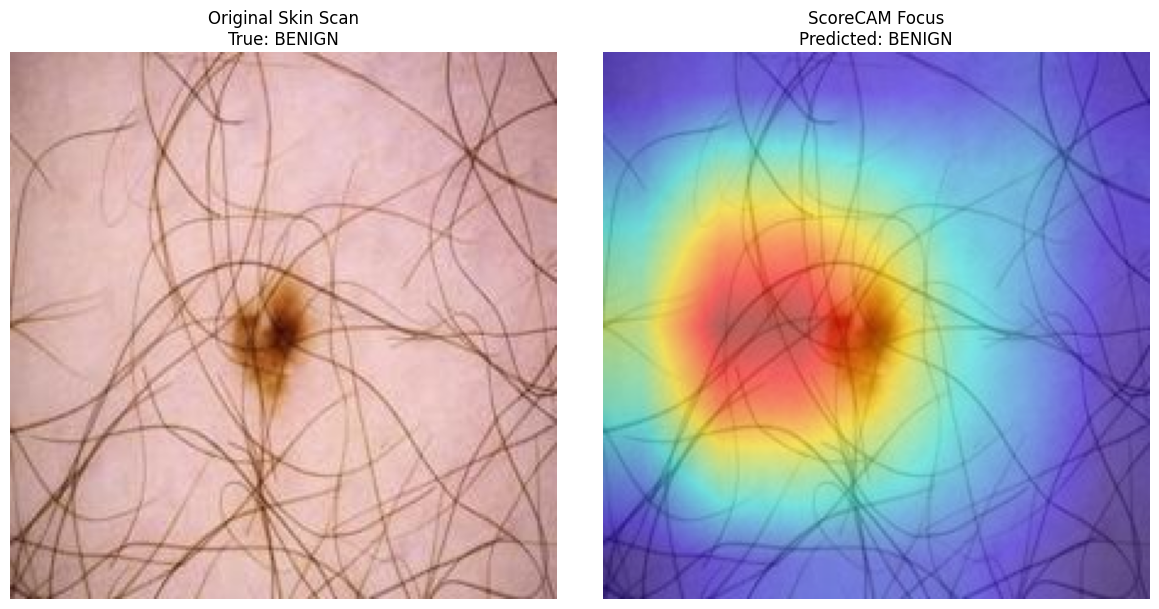

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from pytorch_grad_cam import ScoreCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

model.eval()
target_layers = [model.layer4[-1]]

test_image, true_label_idx = next(iter(test_loader))
input_tensor = test_image.to(device)


with torch.no_grad():
    output = model(input_tensor)
    pred_label_idx = torch.argmax(output, dim=1).item()

true_class = class_names[true_label_idx.item()]
pred_class = class_names[pred_label_idx]
print(f"True Diagnosis: {true_class} | Model Prediction: {pred_class}")

targets = [ClassifierOutputTarget(pred_label_idx)]

print("Generating ScoreCAM Heatmap...")
with ScoreCAM(model=model, target_layers=target_layers) as cam:
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]

inv_normalize = transforms.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)
rgb_img = inv_normalize(test_image.squeeze()).cpu().permute(1, 2, 0).numpy()
rgb_img = np.clip(rgb_img, 0, 1)

visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))

ax[0].imshow(rgb_img)
ax[0].set_title(f"Original Skin Scan\nTrue: {true_class.upper()}")
ax[0].axis('off')

ax[1].imshow(visualization)
ax[1].set_title(f"ScoreCAM Focus\nPredicted: {pred_class.upper()}")
ax[1].axis('off')

plt.tight_layout()
plt.show()

fig.savefig("melanoma_scorecam_result.png", dpi=300)

True Diagnosis: MALIGNANT | Model Prediction: MALIGNANT
Generating all 8 CAM heatmaps... (Note: ScoreCAM & AblationCAM take a moment)


100%|██████████| 16/16 [00:00<00:00, 33.96it/s]


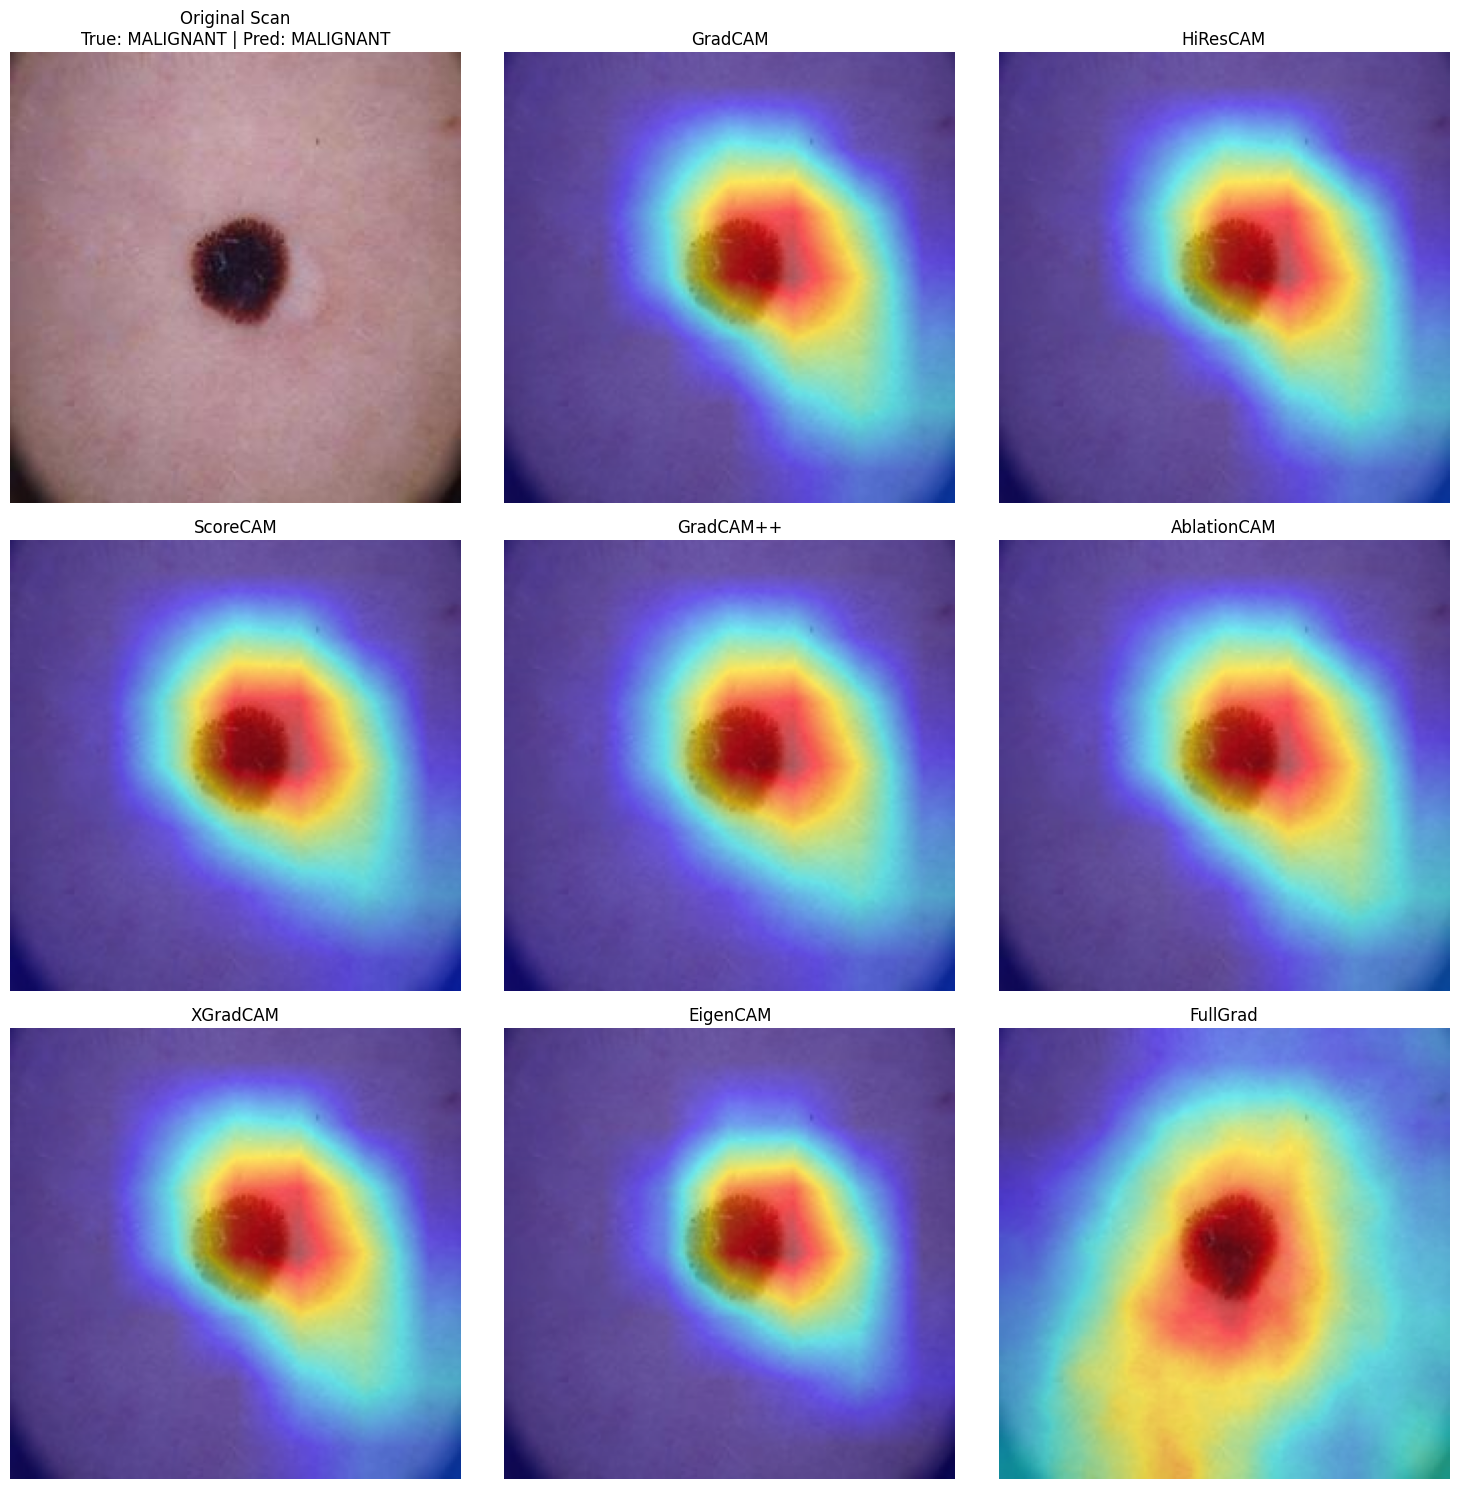

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torchvision import transforms
from pytorch_grad_cam import (
    GradCAM, HiResCAM, ScoreCAM, GradCAMPlusPlus,
    AblationCAM, XGradCAM, EigenCAM, FullGrad
)
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# 1. Set model to evaluation mode & target the final ResNet block
model.eval()
target_layers = [model.layer4[-1]]

# 2. Grab ONE image from the melanoma test loader
test_image, true_label_idx = next(iter(test_loader))
input_tensor = test_image.to(device)

# 3. Get the Model's Prediction
with torch.no_grad():
    output = model(input_tensor)
    pred_label_idx = torch.argmax(output, dim=1).item()

true_class = class_names[true_label_idx.item()]
pred_class = class_names[pred_label_idx]
print(f"True Diagnosis: {true_class.upper()} | Model Prediction: {pred_class.upper()}")

# 4. Define the 8 CAM Algorithms
cam_algorithms = {
    "GradCAM": GradCAM,
    "HiResCAM": HiResCAM,
    "ScoreCAM": ScoreCAM,
    "GradCAM++": GradCAMPlusPlus,
    "AblationCAM": AblationCAM,
    "XGradCAM": XGradCAM,
    "EigenCAM": EigenCAM,
    "FullGrad": FullGrad
}

# Target the PREDICTED class to see the model's actual reasoning
targets = [ClassifierOutputTarget(pred_label_idx)]

# 5. Denormalize the Image for Matplotlib
inv_normalize = transforms.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)
rgb_img = inv_normalize(test_image.squeeze()).cpu().permute(1, 2, 0).numpy()
rgb_img = np.clip(rgb_img, 0, 1) # Lock values between 0 and 1

# 6. Set up a gorgeous 3x3 grid
fig, axes = plt.subplots(3, 3, figsize=(15, 15))
axes = axes.flatten()

# Plot the Original Image in the top left slot
axes[0].imshow(rgb_img)
axes[0].set_title(f"Original Scan\nTrue: {true_class.upper()} | Pred: {pred_class.upper()}")
axes[0].axis('off')

print("Generating all 8 CAM heatmaps... (Note: ScoreCAM & AblationCAM take a moment)")

# 7. Loop, Generate, and Plot
for i, (name, cam_class) in enumerate(cam_algorithms.items()):
    with cam_class(model=model, target_layers=target_layers) as cam:
        grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
        visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

        # Plot in the next available slot
        axes[i + 1].imshow(visualization)
        axes[i + 1].set_title(name)
        axes[i + 1].axis('off')

plt.tight_layout()
plt.show()

# Save for your final report!
fig.savefig("melanoma_complete_cam_comparison.png", dpi=300)

True Diagnosis: BENIGN | Model Prediction: BENIGN
Generating all 8 CAM heatmaps... (Note: ScoreCAM & AblationCAM take a moment)


100%|██████████| 16/16 [00:00<00:00, 31.15it/s]


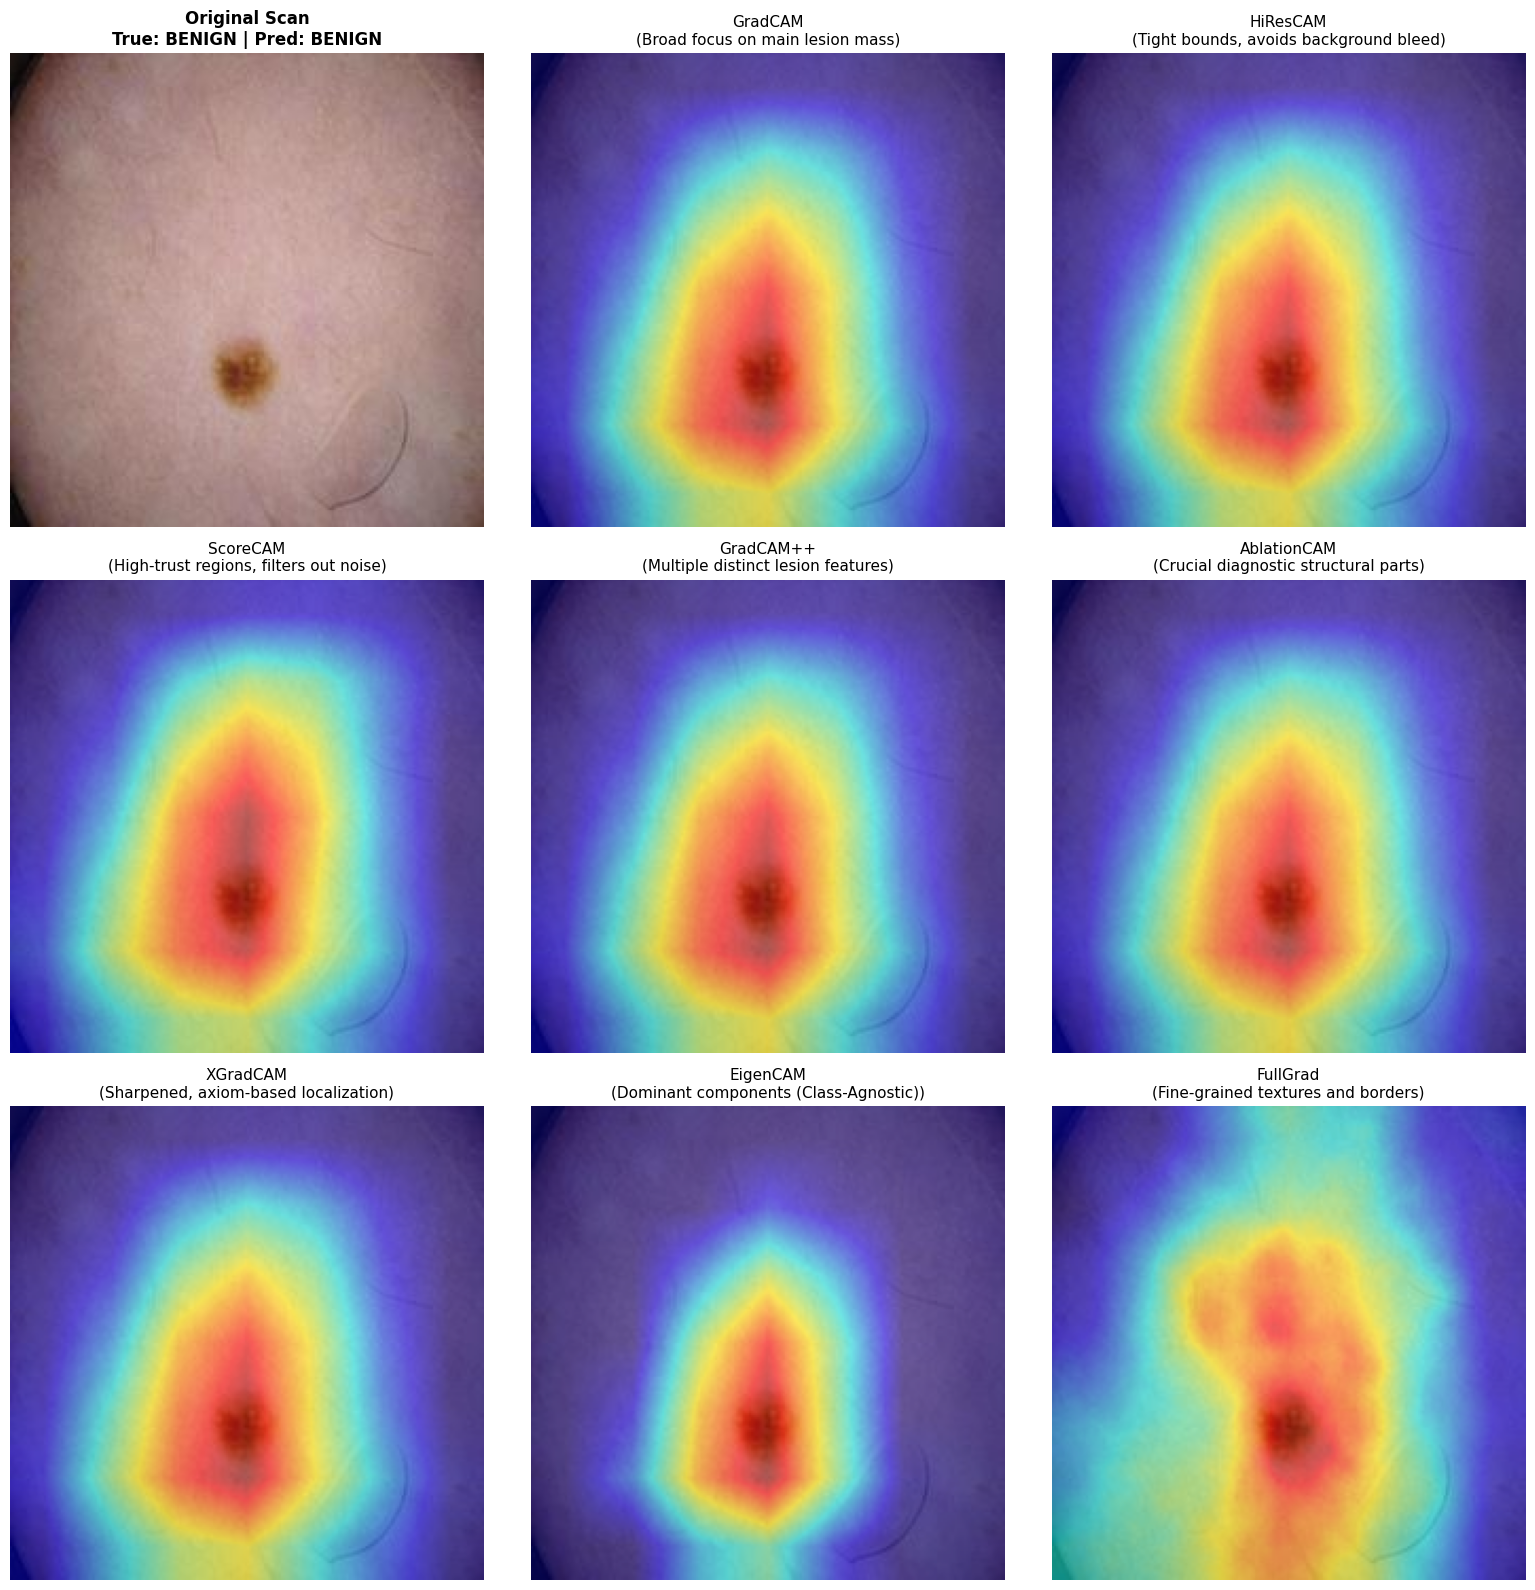

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torchvision import transforms
from pytorch_grad_cam import (
    GradCAM, HiResCAM, ScoreCAM, GradCAMPlusPlus,
    AblationCAM, XGradCAM, EigenCAM, FullGrad
)
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# 1. Set model to evaluation mode & target the final ResNet block
model.eval()
target_layers = [model.layer4[-1]]

# 2. Grab ONE image from the melanoma test loader
test_image, true_label_idx = next(iter(test_loader))
input_tensor = test_image.to(device)

# 3. Get the Model's Prediction
with torch.no_grad():
    output = model(input_tensor)
    pred_label_idx = torch.argmax(output, dim=1).item()

true_class = class_names[true_label_idx.item()]
pred_class = class_names[pred_label_idx]
print(f"True Diagnosis: {true_class.upper()} | Model Prediction: {pred_class.upper()}")

# 4. Define the 8 CAM Algorithms WITH Descriptions for the Plot Titles
cam_algorithms = {
    "GradCAM": (GradCAM, "Broad focus on main lesion mass"),
    "HiResCAM": (HiResCAM, "Tight bounds, avoids background bleed"),
    "ScoreCAM": (ScoreCAM, "High-trust regions, filters out noise"),
    "GradCAM++": (GradCAMPlusPlus, "Multiple distinct lesion features"),
    "AblationCAM": (AblationCAM, "Crucial diagnostic structural parts"),
    "XGradCAM": (XGradCAM, "Sharpened, axiom-based localization"),
    "EigenCAM": (EigenCAM, "Dominant components (Class-Agnostic)"),
    "FullGrad": (FullGrad, "Fine-grained textures and borders")
}

# Target the PREDICTED class to see the model's actual reasoning
targets = [ClassifierOutputTarget(pred_label_idx)]

# 5. Denormalize the Image for Matplotlib
inv_normalize = transforms.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)
rgb_img = inv_normalize(test_image.squeeze()).cpu().permute(1, 2, 0).numpy()
rgb_img = np.clip(rgb_img, 0, 1) # Lock values between 0 and 1

# 6. Set up a gorgeous 3x3 grid with extra vertical space for subtitles
fig, axes = plt.subplots(3, 3, figsize=(16, 16))
fig.subplots_adjust(hspace=0.3) # Add space between rows for the text
axes = axes.flatten()

# Plot the Original Image in the top left slot
axes[0].imshow(rgb_img)
axes[0].set_title(f"Original Scan\nTrue: {true_class.upper()} | Pred: {pred_class.upper()}", fontsize=12, fontweight='bold')
axes[0].axis('off')

print("Generating all 8 CAM heatmaps... (Note: ScoreCAM & AblationCAM take a moment)")

# 7. Loop, Generate, and Plot with Annotations
for i, (name, (cam_class, description)) in enumerate(cam_algorithms.items()):
    with cam_class(model=model, target_layers=target_layers) as cam:
        grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
        visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

        # Plot in the next available slot
        axes[i + 1].imshow(visualization)

        # Add the Name and the Description as a multi-line title
        title_text = f"{name}\n({description})"
        axes[i + 1].set_title(title_text, fontsize=11)
        axes[i + 1].axis('off')

plt.tight_layout()
plt.show()

# Save for your final report!
fig.savefig("melanoma_annotated_cam_comparison.png", dpi=300, bbox_inches='tight')